In [3]:
import pandas as pd
import numpy as np

sample_meta = pd.read_csv('./metadata_files/master_sample_metadata_111226.csv')
peps_meta = pd.read_csv('./metadata_files/lassa_library_sequences_species_standardized_070726_ICTV_corrected.csv')
peps_metadata = peps_meta.set_index('seq_id')


df= pd.read_csv('./output_files/long_spec_0_98_111226.csv')


In [23]:
df_lassa = df.loc[df['species'] == 'Mammarenavirus lassaense']

In [24]:
lassa_max_per_protein = df_lassa.groupby(['protein_std', 'individual'])['z_score'].max().reset_index()

In [25]:
lassa_max_wide = lassa_max_per_protein.pivot_table(values='z_score', index='protein_std', columns='individual')

In [36]:
n_reactive_proteins = (
    df[
        (df['species'] == 'Mammarenavirus lassaense') & 
        (df['reactive'] == True)
    ]
    .groupby('individual')['protein_std']
    .nunique()
)

passing_individuals = n_reactive_proteins[n_reactive_proteins >= 3].index

#everyone else fails
failing_individuals = lassa_max_wide.columns.difference(passing_individuals)

print("Passing", len(passing_individuals))
print("Failing", len(failing_individuals))

#keep everyone, but set failing individuals to zero
lassa_max_wide_filtered = lassa_max_wide.copy()
lassa_max_wide_filtered.loc[:, failing_individuals] = 0

Passing 266
Failing 218


In [46]:
passing_individuals.to_series().to_csv('./output_files/passing_individuals_pep_reactive_min_3_lasv_proteins.csv', index=False, header=['individual'])

### Repeat matrix showing max z score for each protein across the cohort with the condition that peptides from at least 2 LASV proteins need to be reactive

In [37]:
c_cols = lassa_max_wide_filtered.filter(regex='C-').columns
s_cols = lassa_max_wide_filtered.filter(regex='S-').columns
hbdb_cols = lassa_max_wide_filtered.filter(regex='HBDB').columns

In [38]:
lassa_max_wide_filtered = lassa_max_wide_filtered.loc[:, list(c_cols) + list(s_cols) + list(hbdb_cols)]

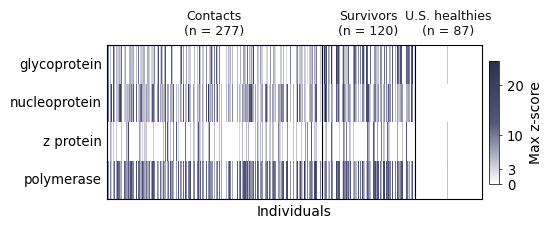

In [48]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from fig_style import apply_style

apply_style()

TEXT_COLOR = "#111111"

cmap = sns.light_palette("#2E3050", as_cmap=True)

# Group sizes / labels (rename to match your study)
groups = [
    ("Contacts",   len(c_cols)),
    ("Survivors",  len(s_cols)),
    ("U.S. healthies", len(hbdb_cols)),
]

fig, ax = plt.subplots(figsize=(5.8, 2))

#clip everything under z score 3 to 0 -> will turn white
plot_data = lassa_max_wide_filtered.where(lassa_max_wide >= 3, 0) 

PROTEIN_ORDER = ["glycoprotein", "nucleoprotein",  "z protein", "polymerase"]

plot_data = plot_data.loc[PROTEIN_ORDER]

sns.heatmap(
    data=plot_data,
    vmin=0, vmax=25,
    cmap = sns.blend_palette(["#FFFFFF", "#53557C", "#2E3050"], as_cmap=True),
    xticklabels=False,
    ax=ax,
    rasterized=True,
    cbar_kws=dict(
        label="Max z-score",   # <- your actual metric
        shrink=0.8, aspect=12, pad=0.015,
        ticks=[0, 3, 10, 20],
    ),
)

# Group separators + labels on top
edges = np.cumsum([n for _, n in groups])
starts = np.r_[0, edges[:-1]]

for x in edges[:-1]:
    ax.axvline(x, color="white", linewidth=2)

for (name, n), x0 in zip(groups, starts):
    ax.text(x0 + n / 2, -0.2, f"{name}\n(n = {n})",
            ha="center", va="bottom", fontsize=9, color=TEXT_COLOR)

ax.set_xlabel("Individuals")
ax.set_ylabel("")
ax.tick_params(axis="y", length=0)
ax.set_yticklabels(ax.get_yticklabels(), rotation=0)
for x in edges[:-1]:
    ax.axvline(x, color="black", linewidth=0.8)

cbar = ax.collections[0].colorbar
cbar.outline.set_linewidth(0.5)
cbar.ax.tick_params(width=0.5, length=2)


for spine in ax.spines.values():
    spine.set_visible(True)
    spine.set_color("black")
    spine.set_linewidth(0.8)

fig.savefig("./output_figures/Fig_LASV_heatmap_pep_reactive_to_3_proteins.svg",
            bbox_inches="tight", transparent=True)
plt.show()